<font color="#0D9DF0"><h3><b>ANÁLISE DESCRITIVA — EDUCAÇÃO, LONGEVIDADE E TRANSPORTE</b></h3></font>

**Base principal:** Gapminder (1952–2007)  
**Bases secundárias:** Our World in Data, Banco Mundial (LPI) e CNT  
**Perguntas:** 6 a 9  
**Foco:** coleta, tratamento e análise descritiva em Python, com cruzamento por país e ano


## Objetivo

Este notebook responde às quatro perguntas abaixo a partir do Gapminder e de bases secundárias já baixadas em `data_base/`. O recorte é descritivo: importar, limpar, unir e visualizar. Não há modelagem causal.


### Perguntas

**6.** Como o PIB se relaciona com o nível de escolaridade do país?

**7.** Países com maior gasto público em educação (% do PIB) apresentam maior longevidade?

**8.** Como o investimento no transporte impacta no nível de escolaridade por país?

**9.** Quais regiões brasileiras são mais afetadas com o desperdício e perda de carga e existe relação com o nível e a qualidade das estradas? Qual outro fator impacta mais?


### Fontes utilizadas

| Pergunta | Arquivo | Origem | Papel |
| --- | --- | --- | --- |
| 6, 7 e 8 | `gapminder_full.csv` | Gapminder | PIB per capita, expectativa de vida, população, continente |
| 6 e 8 | `mean-years-of-schooling-long-run.csv` | Our World in Data | Média de anos de escolaridade |
| 7 | `government-spending-on-education-as-a-share-of-gdp.csv` | Our World in Data | Gasto público em educação (% do PIB) |
| 8 | `API_LP.LPI.INFR.XQ_DS2_en_csv_v2_5744.csv` | Banco Mundial | Nota de qualidade da infraestrutura de transporte (LPI, 1 a 5) |
| 9 | `qualidade_rodovias.xlsx` | CNT — Pesquisa de Rodovias | Estado geral, pavimento, sinalização e geometria por trecho/UF |

A pergunta 8 usa a **nota de qualidade da infraestrutura** do Logistics Performance Index, que é o arquivo de transporte disponível na pasta. Não há série de investimento em transporte em % do PIB neste diretório.

A pergunta 9 **não tem base de perda de carga** em `data_base/`. A análise fica restrita à qualidade das rodovias por região, e a geometria entra como o outro fator disponível para comparar com o estado geral.


### Etapas do notebook

1. Coleta e exploração inicial
2. Limpeza do Gapminder e padronização de nomes de países
3. Pergunta 6 — PIB e escolaridade
4. Pergunta 7 — gasto em educação e longevidade
5. Pergunta 8 — infraestrutura de transporte e escolaridade
6. Pergunta 9 — qualidade das rodovias por região brasileira
7. Síntese


#### Importação das bibliotecas


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11


---

## 1. Coleta de Dados

Os CSVs da OWID já vêm no formato longo (país, ano, valor). O arquivo do Banco Mundial vem no formato largo (um ano por coluna) e tem quatro linhas de cabeçalho institucional. A planilha da CNT tem uma aba com um trecho de rodovia por linha.


In [2]:
PASTA = "data_base"

df_gap = pd.read_csv(f"{PASTA}/gapminder_full.csv")
df_esc = pd.read_csv(f"{PASTA}/mean-years-of-schooling-long-run.csv")
df_gasto = pd.read_csv(f"{PASTA}/government-spending-on-education-as-a-share-of-gdp.csv")
df_lpi = pd.read_csv(
    f"{PASTA}/API_LP.LPI.INFR.XQ_DS2_en_csv_v2_5744.csv",
    skiprows=4,
)
df_rodovias = pd.read_excel(f"{PASTA}/qualidade_rodovias.xlsx")

print("Gapminder:", df_gap.shape)
print("Escolaridade (OWID):", df_esc.shape)
print("Gasto em educação (OWID):", df_gasto.shape)
print("LPI infraestrutura (Banco Mundial):", df_lpi.shape)
print("Rodovias CNT:", df_rodovias.shape)


Gapminder: (1736, 6)
Escolaridade (OWID): (3699, 4)
Gasto em educação (OWID): (5205, 4)
LPI infraestrutura (Banco Mundial): (266, 71)
Rodovias CNT: (1291, 8)


Amostra de cada base, para conferir colunas e o formato antes de qualquer transformação.


In [3]:
display(df_gap.head())
display(df_esc.head())
display(df_gasto.head())
display(df_lpi.iloc[:5, :8])
display(df_rodovias.head())


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


,Entity,Code,Year,Average years of schooling
0,Afghanistan,AFG,1870,0.01
1,Afghanistan,AFG,1875,0.01
2,Afghanistan,AFG,1880,0.01
3,Afghanistan,AFG,1885,0.01
4,Afghanistan,AFG,1890,0.01


,Entity,Code,Year,Total across all levels of education
0,Afghanistan,AFG,2010,3.47945
1,Afghanistan,AFG,2011,3.46201
2,Afghanistan,AFG,2012,2.60421
3,Afghanistan,AFG,2013,3.45446
4,Afghanistan,AFG,2014,3.69522


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963
0,Aruba,ABW,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
4,Angola,AGO,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN


,Rodovia,UF,Extensão,Estado Geral,Pavimento,Sinalização,Geometria,Em obra
0,AC-010,AC,58.0,Péssimo,Ruim,Péssimo,Péssimo,NaN
1,AC-010,AC,9.0,Ruim,Ruim,Regular,Péssimo,Sim
2,AC-040,AC,12.0,Ruim,Ruim,Regular,Ruim,NaN
3,AC-040,AC,10.0,Ruim,Ruim,Regular,Regular,Sim
4,AC-307,AC,12.0,Péssimo,Regular,Péssimo,Péssimo,NaN


## 2. Exploração e limpeza do Gapminder

A base principal cobre 1952–2007 em intervalos de cinco anos. É o eixo dos cruzamentos das perguntas 6 a 8.


In [4]:
print("Colunas:", df_gap.columns.tolist())
print("Anos:", sorted(df_gap["year"].unique()))
print("Países:", df_gap["country"].nunique())
print("Continentes:", sorted(df_gap["continent"].dropna().unique()))
print()
print("Valores ausentes por coluna:")
print(df_gap.isnull().sum())
print()
print("Linhas duplicadas:", int(df_gap.duplicated().sum()))
display(df_gap.describe().round(2))


Colunas: ['country', 'year', 'pop', 'continent', 'lifeExp', 'gdpPercap']
Anos: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Países: 142
Continentes: ['Africa', 'Americas', 'Asia', 'Europe', 'Oceania']

Valores ausentes por coluna:
country      0
year         0
pop          0
continent    0
lifeExp      0
gdpPercap    0
dtype: int64

Linhas duplicadas: 32


,year,pop,lifeExp,gdpPercap
count,1736.00,1.736000e+03,1736.00,1736.00
mean,1979.67,3.156800e+07,59.51,7240.16
std,17.30,1.172888e+08,12.96,9839.87
min,1952.00,6.001100e+04,23.60,241.17
25%,1967.00,2.818694e+06,48.24,1202.06
50%,1982.00,7.150606e+06,60.81,3534.77
75%,1997.00,1.977102e+07,70.94,9380.25
max,2007.00,1.318683e+09,82.60,113523.13


In [6]:
df_gap.dtypes

country          str
year           int64
pop          float64
continent        str
lifeExp      float64
gdpPercap    float64
dtype: object

In [7]:
n_antes = len(df_gap)
df_gap = df_gap.drop_duplicates()
df_gap['pop'] = df_gap['pop'].astype(int)
print(f"Duplicatas removidas: {n_antes - len(df_gap)}")
print(f"Registros restantes: {len(df_gap)}")

df_gap_2007 = df_gap.query("year == 2007").copy()
print(f"Países em 2007: {df_gap_2007['country'].nunique()}")


Duplicatas removidas: 0
Registros restantes: 1704
Países em 2007: 142


**Decisões de tratamento do Gapminder**

- Não havia valores ausentes nas seis colunas.
- 32 linhas duplicadas foram removidas; restaram 1.704 registros (142 países × 12 anos).
- Os tipos já estavam adequados, com exceção de pop que estava em float e foi para int.


## 3. Padronização de nomes de países

fazendo a padronização dos dados para o merge com o Gapminder


In [8]:
NOME_PARA_GAPMINDER = {
    "Czechia": "Czech Republic",
    "Democratic Republic of Congo": "Congo Dem. Rep.",
    "Congo": "Congo Rep.",
    "Congo, Dem. Rep.": "Congo Dem. Rep.",
    "Congo, Rep.": "Congo Rep.",
    "Eswatini": "Swaziland",
    "Hong Kong": "Hong Kong China",
    "Hong Kong SAR, China": "Hong Kong China",
    "South Korea": "Korea Rep.",
    "Korea, Rep.": "Korea Rep.",
    "Korea, Dem. People's Rep.": "Korea Dem. Rep.",
    "Yemen": "Yemen Rep.",
    "Yemen, Rep.": "Yemen Rep.",
    "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia",
    "Iran, Islamic Rep.": "Iran",
    "Syrian Arab Republic": "Syria",
    "Venezuela, RB": "Venezuela",
    "Viet Nam": "Vietnam",
    "Turkiye": "Turkey",
    "Slovakia": "Slovak Republic",
    "Somalia, Fed. Rep.": "Somalia",
}


def padroniza_pais(serie):
    return serie.replace(NOME_PARA_GAPMINDER)


def correlacoes(df, x, y):
    pearson = df[x].corr(df[y])
    # Spearman = Pearson das posições de ranking (não exige SciPy)
    spearman = df[x].rank().corr(df[y].rank())
    print(f"Pearson:  {pearson:.3f}")
    print(f"Spearman: {spearman:.3f}")
    print(f"N:        {len(df)}")
    return pearson, spearman


def paises_sem_dado(df, coluna):
    faltantes = sorted(df.loc[df[coluna].isna(), "country"].unique())
    print(f"Países do Gapminder sem {coluna}: {len(faltantes)}")
    if faltantes:
        print(", ".join(faltantes))
    return faltantes


---

## Pergunta 6 — Como o PIB se relaciona com o nível de escolaridade do país?

**Recorte de ano.** O gapminder termina em 2007 e OWID possui dados de 5 em 5 anos, porém não possui para 2007, dessa forma o ano utilizado como referência foi 2005 para correlacionar os dados

### 6.1 Tratamento


In [9]:
df_esc_2005 = df_esc.query("Year == 2005").copy()
df_esc_2005["country"] = padroniza_pais(df_esc_2005["Entity"])
df_esc_2005 = df_esc_2005.rename(
    columns={"Average years of schooling": "anos_escolaridade"}
)

df_q6 = df_gap_2007.merge(
    df_esc_2005[["country", "anos_escolaridade"]],
    on="country",
    how="left",
)

print("Linhas após o left join:", len(df_q6))
print("Nulos em anos_escolaridade:", int(df_q6["anos_escolaridade"].isna().sum()))
paises_sem_dado(df_q6, "anos_escolaridade")

df_q6_ok = df_q6.dropna(subset=["anos_escolaridade"]).copy()
print()
print("Países na análise:", len(df_q6_ok))
display(df_q6_ok[["country", "continent", "gdpPercap", "anos_escolaridade"]].head())


Linhas após o left join: 142
Nulos em anos_escolaridade: 39
Países do Gapminder sem anos_escolaridade: 39
Angola, Bahrain, Bosnia and Herzegovina, Botswana, Burkina Faso, Burundi, Central African Republic, Chad, Comoros, Congo Rep., Croatia, Djibouti, Equatorial Guinea, Eritrea, Ethiopia, Gabon, Guinea, Guinea-Bissau, Israel, Korea Dem. Rep., Lebanon, Madagascar, Mauritania, Mongolia, Montenegro, Namibia, Nigeria, Oman, Puerto Rico, Rwanda, Sao Tome and Principe, Saudi Arabia, Singapore, Slovak Republic, Slovenia, Somalia, Tanzania, Vietnam, West Bank and Gaza

Países na análise: 103


,country,continent,gdpPercap,anos_escolaridade
0,Afghanistan,Asia,974.580338,3.32
1,Albania,Europe,5937.029526,10.24
2,Algeria,Africa,6223.367465,6.43
4,Argentina,Americas,12779.379640,9.57
5,Australia,Oceania,34435.367440,11.71




### 6.2 Análise


In [10]:
print("Correlação entre PIB per capita e anos de escolaridade")
correlacoes(df_q6_ok, "gdpPercap", "anos_escolaridade")
print()
print("Medianas por continente")
display(
    df_q6_ok.groupby("continent")[["gdpPercap", "anos_escolaridade"]]
    .median()
    .round(2)
    .sort_values("anos_escolaridade")
)


Correlação entre PIB per capita e anos de escolaridade
Pearson:  0.742
Spearman: 0.858
N:        103

Medianas por continente


,gdpPercap,anos_escolaridade
continent,,
Africa,1463.25,5.11
Asia,4184.55,6.68
Americas,8178.50,8.51
Europe,30470.02,10.89
Oceania,29810.19,11.86


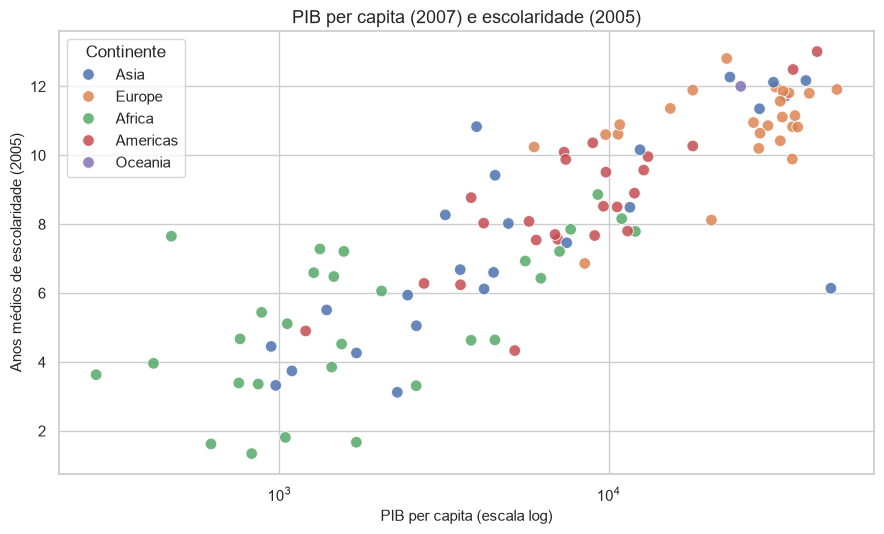

In [11]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df_q6_ok,
    x="gdpPercap",
    y="anos_escolaridade",
    hue="continent",
    alpha=0.85,
    s=70,
    ax=ax,
)
ax.set_xscale("log")
ax.set_xlabel("PIB per capita (escala log)")
ax.set_ylabel("Anos médios de escolaridade (2005)")
ax.set_title("PIB per capita (2007) e escolaridade (2005)")
ax.legend(title="Continente")
plt.tight_layout()
plt.show()


**Conclusão — pergunta 6.** Há uma relação positiva e forte entre PIB per capita e anos de escolaridade: Pearson **0,74** e Spearman **0,86**, com **103 países**. A Spearman mais alta indica uma associação monotônica ainda mais clara do que a linear. No gráfico (eixo X em log), África concentra a parte inferior esquerda e Europa/Oceania a parte superior direita. Países mais ricos, neste recorte, também apresentam população adulta com mais anos de estudo.


---

## Pergunta 7 — Países com maior gasto público em educação (% do PIB) apresentam maior longevidade?


**Tratamento.** Left join pelo nome do país e exclusão dos países sem gasto naquele ano. O indicador já está em % do PIB, então não há conversão de moeda.

Ambas as bases consideram o mesmo recorte de data, utilizando 2007 como referência


### 7.1 Tratamento


In [12]:
df_gasto_2007 = df_gasto.query("Year == 2007").copy()
df_gasto_2007["country"] = padroniza_pais(df_gasto_2007["Entity"])
df_gasto_2007 = df_gasto_2007.rename(
    columns={"Total across all levels of education": "gasto_educ_pct_pib"}
)

df_q7 = df_gap_2007.merge(
    df_gasto_2007[["country", "gasto_educ_pct_pib"]],
    on="country",
    how="left",
)

print("Nulos em gasto_educ_pct_pib:", int(df_q7["gasto_educ_pct_pib"].isna().sum()))
paises_sem_dado(df_q7, "gasto_educ_pct_pib")

df_q7_ok = df_q7.dropna(subset=["gasto_educ_pct_pib"]).copy()
print()
print("Países na análise:", len(df_q7_ok))
display(df_q7_ok[["country", "continent", "gasto_educ_pct_pib", "lifeExp", "pop"]].head())
display(df_q7_ok[["gasto_educ_pct_pib", "lifeExp"]].describe().round(2))


Nulos em gasto_educ_pct_pib: 64
Países do Gapminder sem gasto_educ_pct_pib: 64
Afghanistan, Algeria, Angola, Australia, Belgium, Bosnia and Herzegovina, Burundi, Chad, China, Comoros, Congo Dem. Rep., Congo Rep., Ecuador, Equatorial Guinea, Eritrea, France, Gabon, Germany, Greece, Guinea, Guinea-Bissau, Haiti, Honduras, India, Iraq, Jordan, Kenya, Korea Dem. Rep., Korea Rep., Kuwait, Lesotho, Liberia, Libya, Malawi, Mali, Mauritania, Montenegro, Morocco, Mozambique, Myanmar, Namibia, New Zealand, Nicaragua, Nigeria, Oman, Panama, Puerto Rico, Reunion, Saudi Arabia, Senegal, Somalia, Sri Lanka, Sudan, Swaziland, Taiwan, Trinidad and Tobago, Turkey, Uganda, United States, Uruguay, Vietnam, West Bank and Gaza, Yemen Rep., Zimbabwe

Países na análise: 78


,country,continent,gasto_educ_pct_pib,lifeExp,pop
1,Albania,Europe,3.14639,76.423,3600523
4,Argentina,Americas,4.46261,75.320,40301927
6,Austria,Europe,5.17918,79.829,8199783
7,Bahrain,Asia,2.57500,75.635,708573
8,Bangladesh,Asia,2.20222,64.062,150448339


,gasto_educ_pct_pib,lifeExp
count,78.00,78.00
mean,4.20,69.47
std,1.81,10.93
min,0.82,42.38
25%,3.02,63.85
50%,4.06,72.68
75%,4.92,78.23
max,11.87,82.60


### 7.2 Análise


In [13]:
print("Correlação entre gasto em educação (% do PIB) e expectativa de vida")
correlacoes(df_q7_ok, "gasto_educ_pct_pib", "lifeExp")


Correlação entre gasto em educação (% do PIB) e expectativa de vida
Pearson:  0.276
Spearman: 0.397
N:        78


(np.float64(0.275842021284774), np.float64(0.39693218174230827))

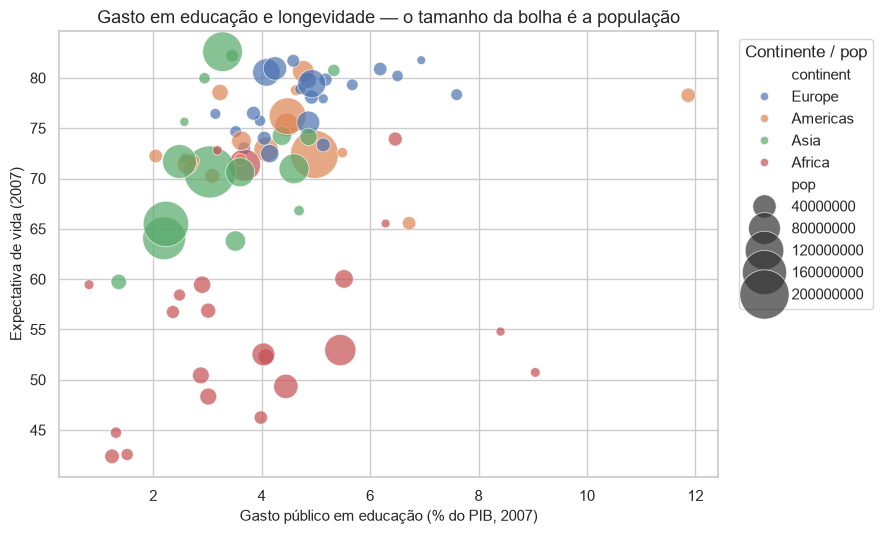

In [14]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df_q7_ok,
    x="gasto_educ_pct_pib",
    y="lifeExp",
    hue="continent",
    size="pop",
    sizes=(40, 1400),
    alpha=0.7,
    ax=ax,
)
ax.set_xlabel("Gasto público em educação (% do PIB, 2007)")
ax.set_ylabel("Expectativa de vida (2007)")
ax.set_title("Gasto em educação e longevidade — o tamanho da bolha é a população")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Continente / pop")
plt.tight_layout()
plt.show()


**Conclusão — pergunta 7.** Com **78 países** em 2007, a associação é só fraca a moderada: Pearson **0,28** e Spearman **0,40**. A nuvem sobe pouco; 
Não é possível inferir que a correlação ou causalidade nesse caso pois há países com gastos baixos e expectativa de longevidade alta, e o contrário também, dessa forma concluí-se que a hipótese é fraca.


---

## Pergunta 8 — Como o investimento no transporte impacta no nível de escolaridade por país?

**Por que esta base?** Não há, na pasta, uma série de investimento em transporte em % do PIB. O arquivo do Banco Mundial traz o subindicador do LPI *Quality of trade and transport-related infrastructure* (nota de 1 a 5). É um escore de qualidade, já comparável entre países, sem conversão de moeda nem inflação.

**Recorte de ano.** O LPI tem 2007, mas a escolaridade da OWID não. Os dois indicadores existem em **2010**. O continente vem do Gapminder (atributo do país) só para colorir o gráfico.

**Tratamento.** O CSV do Banco Mundial está largo. Um `melt` transforma os anos em linhas. Depois, `pd.cut` parte a nota LPI em três faixas de quantis (Baixo, Médio, Alto).


### 8.1 Tratamento


In [15]:
colunas_ano = [c for c in df_lpi.columns if str(c).isdigit()]

df_lpi_longo = df_lpi.melt(
    id_vars=["Country Name", "Country Code"],
    value_vars=colunas_ano,
    var_name="year",
    value_name="lpi_infra",
)
df_lpi_longo["year"] = df_lpi_longo["year"].astype(int)
df_lpi_longo["country"] = padroniza_pais(df_lpi_longo["Country Name"])

df_lpi_2010 = (
    df_lpi_longo.query("year == 2010")
    .dropna(subset=["lpi_infra"])
    .drop_duplicates(subset=["country"], keep="first")
)

df_esc_2010 = df_esc.query("Year == 2010").copy()
df_esc_2010["country"] = padroniza_pais(df_esc_2010["Entity"])
df_esc_2010 = df_esc_2010.rename(
    columns={"Average years of schooling": "anos_escolaridade"}
)

df_q8 = (
    df_gap_2007[["country", "continent"]]
    .merge(df_lpi_2010[["country", "lpi_infra"]], on="country", how="left")
    .merge(df_esc_2010[["country", "anos_escolaridade"]], on="country", how="left")
)

print("Nulos em lpi_infra:", int(df_q8["lpi_infra"].isna().sum()))
print("Nulos em anos_escolaridade:", int(df_q8["anos_escolaridade"].isna().sum()))

df_q8_ok = df_q8.dropna(subset=["lpi_infra", "anos_escolaridade"]).copy()
print("Países na análise:", len(df_q8_ok))

limites = df_q8_ok["lpi_infra"].quantile([0, 1 / 3, 2 / 3, 1]).to_numpy()
print("Limites das faixas (quantis):", np.round(limites, 3))

df_q8_ok["faixa_infra"] = pd.cut(
    df_q8_ok["lpi_infra"],
    bins=limites,
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True,
)

display(
    df_q8_ok.groupby("faixa_infra", observed=True)["anos_escolaridade"]
    .agg(["count", "median", "mean"])
    .round(2)
)


Nulos em lpi_infra: 16
Nulos em anos_escolaridade: 39
Países na análise: 95
Limites das faixas (quantis): [1.61  2.303 3.047 4.34 ]


,count,median,mean
faixa_infra,,,
Baixo,32,6.44,6.64
Médio,31,8.06,7.87
Alto,32,11.58,11.05


### 8.2 Análise


In [16]:
print("Correlação entre nota LPI de infraestrutura e anos de escolaridade")
correlacoes(df_q8_ok, "lpi_infra", "anos_escolaridade")


Correlação entre nota LPI de infraestrutura e anos de escolaridade
Pearson:  0.709
Spearman: 0.716
N:        95


(np.float64(0.7091736901736052), np.float64(0.7164370287279386))

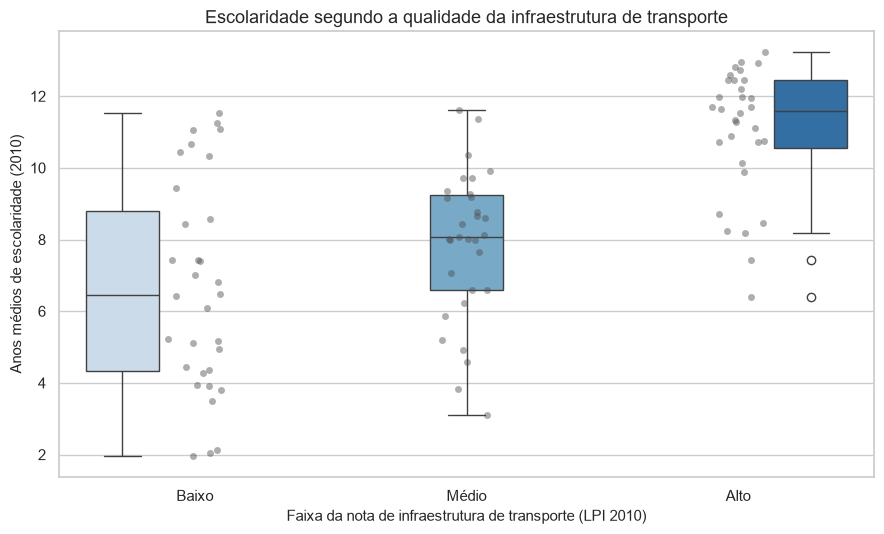

In [17]:
fig, ax = plt.subplots()
sns.boxplot(
    data=df_q8_ok,
    x="faixa_infra",
    y="anos_escolaridade",
    hue="faixa_infra",
    palette="Blues",
    legend=False,
    ax=ax,
)
sns.stripplot(
    data=df_q8_ok,
    x="faixa_infra",
    y="anos_escolaridade",
    color="0.3",
    alpha=0.45,
    size=5,
    ax=ax,
)
ax.set_xlabel("Faixa da nota de infraestrutura de transporte (LPI 2010)")
ax.set_ylabel("Anos médios de escolaridade (2010)")
ax.set_title("Escolaridade segundo a qualidade da infraestrutura de transporte")
plt.tight_layout()
plt.show()


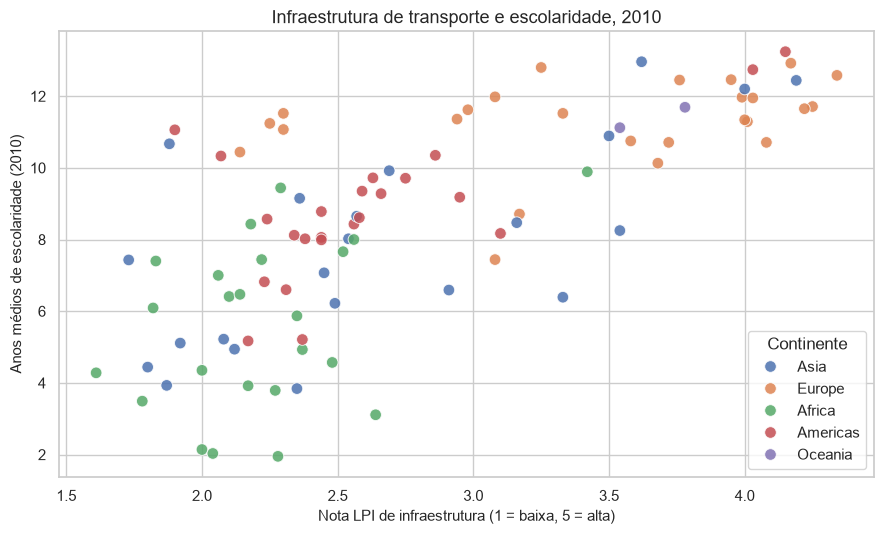

In [18]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df_q8_ok,
    x="lpi_infra",
    y="anos_escolaridade",
    hue="continent",
    alpha=0.85,
    s=70,
    ax=ax,
)
ax.set_xlabel("Nota LPI de infraestrutura (1 = baixa, 5 = alta)")
ax.set_ylabel("Anos médios de escolaridade (2010)")
ax.set_title("Infraestrutura de transporte e escolaridade, 2010")
ax.legend(title="Continente")
plt.tight_layout()
plt.show()


**Conclusão — pergunta 8.** Países com melhor nota de infraestrutura de transporte também têm mais anos de escolaridade. Pearson **0,71** e Spearman **0,72**, com **95 países**. A mediana de escolaridade sobe da faixa Baixa (**6,44** anos) para a Média (**8,06**) e para a Alta (**11,58**). A variável aqui é qualidade da infraestrutura (nota 1 a 5), não o valor investido. 
Os dois indicadores acompanham o nível de desempenho e provam que há uma correlação clara entre as métricas analisadas e o gráfica acima detalha essa afirmação ao analisar os continentes em uma dispersão entre as duas métricas.

---

## Pergunta 9 — Quais regiões brasileiras têm pior qualidade de estrada, e qual dimensão pesa mais?

**Limite desta pergunta.** 


**O que a planilha permite responder.** Qual região concentra maior percentual da malha avaliada em estado geral Ruim ou Péssimo, e qual dimensão (pavimento, sinalização ou geometria) tem mais extensão nessas categorias.

**Tratamento.** As duas últimas linhas da planilha são rodapé do export (`Sem filtros aplicados`) e saem no `dropna`. Cada linha é um trecho, então a agregação é **ponderada pela extensão em km**. Um mapa fixo liga UF à região.


### 9.1 Tratamento


In [19]:
UF_REGIAO = {
    "AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte",
    "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste",
    "PB": "Nordeste", "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste",
    "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}

print("Linhas originais:", len(df_rodovias))
print("Nulos por coluna:")
print(df_rodovias.isnull().sum())

df_rod = df_rodovias.dropna(subset=["UF", "Extensão"]).copy()
df_rod["regiao"] = df_rod["UF"].map(UF_REGIAO)
print()
print("Linhas após remover rodapé/nulos:", len(df_rod))
print("Extensão total (km):", df_rod["Extensão"].sum())
print("UFs sem região:", df_rod["regiao"].isna().sum())
print()
print("Estado geral dos trechos (contagem de linhas, ainda não ponderada):")
print(df_rod["Estado Geral"].value_counts(dropna=False))


Linhas originais: 1291
Nulos por coluna:
Rodovia           1
UF                2
Extensão          2
Estado Geral      2
Pavimento         5
Sinalização       2
Geometria         2
Em obra         856
dtype: int64

Linhas após remover rodapé/nulos: 1289
Extensão total (km): 121805.0
UFs sem região: 0

Estado geral dos trechos (contagem de linhas, ainda não ponderada):
Estado Geral
Regular    616
Bom        339
Ruim       228
Ótimo       57
Péssimo     49
Name: count, dtype: int64


In [20]:
CATEGORIAS_RUINS = ["Ruim", "Péssimo"]
DIMENSOES = ["Estado Geral", "Pavimento", "Sinalização", "Geometria"]


def percentual_ruim(df, coluna):
    validos = df.dropna(subset=[coluna, "Extensão", "regiao"])
    total = validos.groupby("regiao")["Extensão"].sum()
    ruim = (
        validos[validos[coluna].isin(CATEGORIAS_RUINS)]
        .groupby("regiao")["Extensão"]
        .sum()
    )
    return (ruim.reindex(total.index).fillna(0) / total * 100)


tabela_regiao = pd.DataFrame({col: percentual_ruim(df_rod, col) for col in DIMENSOES})
tabela_regiao["extensao_km"] = df_rod.groupby("regiao")["Extensão"].sum()
tabela_regiao = tabela_regiao.sort_values("Estado Geral", ascending=False)

print("Percentual da extensão em Ruim ou Péssimo, por região")
display(tabela_regiao.round(2))

print()
print("Brasil (extensão ponderada)")
for col in DIMENSOES:
    validos = df_rod.dropna(subset=[col, "Extensão"])
    pct = (
        validos.loc[validos[col].isin(CATEGORIAS_RUINS), "Extensão"].sum()
        / validos["Extensão"].sum()
        * 100
    )
    print(f"  {col}: {pct:.2f}%")


Percentual da extensão em Ruim ou Péssimo, por região


,Estado Geral,Pavimento,Sinalização,Geometria,extensao_km
regiao,,,,,
Norte,26.39,31.31,18.48,36.39,14863.0
Nordeste,14.36,17.28,18.47,23.79,32697.0
Sudeste,11.07,15.37,1.35,24.88,32219.0
Sul,9.34,9.61,6.73,25.15,20379.0
Centro-Oeste,3.35,14.50,2.25,11.72,21647.0



Brasil (extensão ponderada)
  Estado Geral: 12.16%
  Pavimento: 16.71%
  Sinalização: 9.10%
  Geometria: 23.70%


### 9.2 Análise


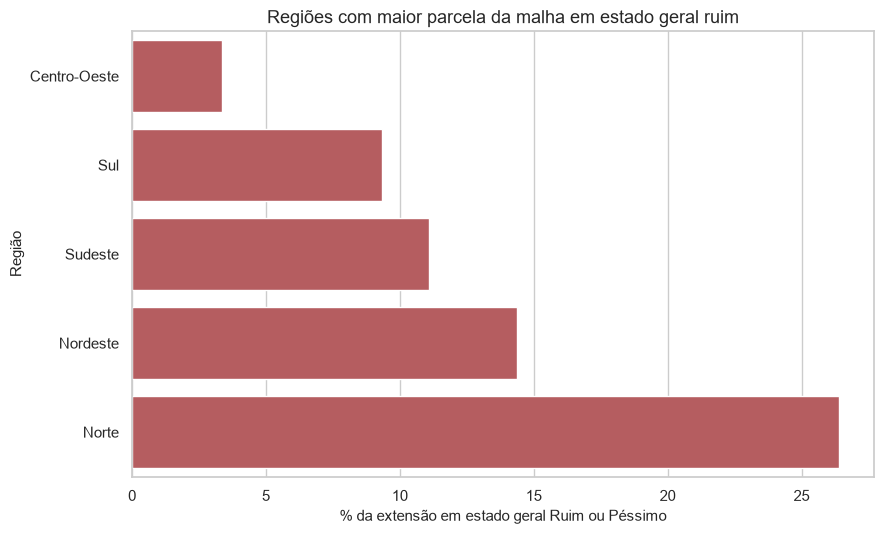

In [21]:
ordem_regioes = tabela_regiao.sort_values("Estado Geral", ascending=True).index.tolist()

fig, ax = plt.subplots()
sns.barplot(
    data=tabela_regiao.reset_index(),
    y="regiao",
    x="Estado Geral",
    order=ordem_regioes,
    color="#c44e52",
    ax=ax,
)
ax.set_xlabel("% da extensão em estado geral Ruim ou Péssimo")
ax.set_ylabel("Região")
ax.set_title("Regiões com maior parcela da malha em estado geral ruim")
plt.tight_layout()
plt.show()


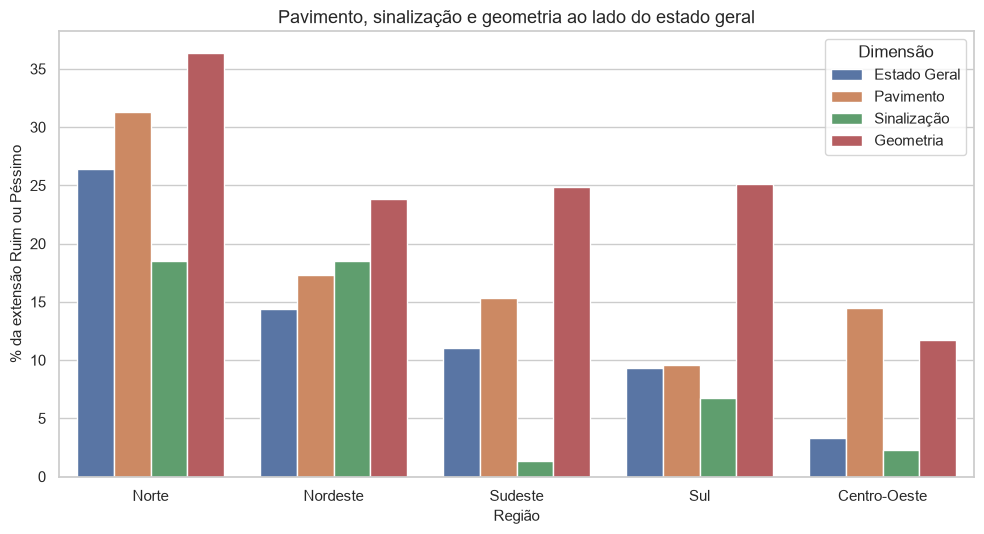

In [22]:
df_dimensoes = (
    tabela_regiao[DIMENSOES]
    .reset_index()
    .melt(id_vars="regiao", var_name="dimensao", value_name="pct_ruim")
)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(
    data=df_dimensoes,
    x="regiao",
    y="pct_ruim",
    hue="dimensao",
    order=["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"],
    ax=ax,
)
ax.set_xlabel("Região")
ax.set_ylabel("% da extensão Ruim ou Péssimo")
ax.set_title("Pavimento, sinalização e geometria ao lado do estado geral")
ax.legend(title="Dimensão")
plt.tight_layout()
plt.show()


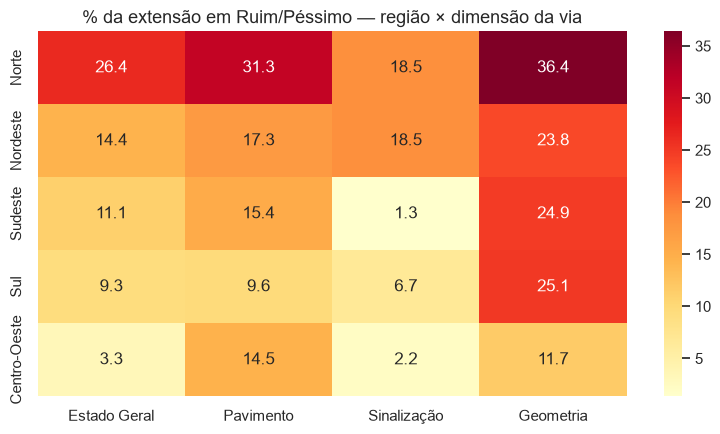

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(
    tabela_regiao[DIMENSOES].loc[
        ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
    ],
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    ax=ax,
)
ax.set_title("% da extensão em Ruim/Péssimo — região × dimensão da via")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


**Conclusão — pergunta 9.** Sem dado de perda de carga, a pergunta regional se responde pela qualidade da malha.

1. **Região mais afetada (estado geral):** o **Norte** tem **26,39%** da extensão avaliada em Ruim ou Péssimo. Seguem Nordeste (14,36%), Sudeste (11,07%), Sul (9,34%) e Centro-Oeste (3,35%).
2. **Relação com as dimensões da via:** o Norte lidera também em pavimento (31,31%) e geometria (36,39%). O Nordeste empata com o Norte na sinalização (~18,5%).
3. **Qual outro fator pesa mais, entre os disponíveis:** no Brasil, a **geometria** concentra a maior parcela de extensão Ruim/Péssimo (**23,70%**), acima do pavimento (16,71%) e da sinalização (9,10%). Entre estado geral, pavimento, sinalização e geometria, a geometria é a dimensão com pior resultado nacional.


---

## Síntese

| Pergunta | Recorte | N | Resultado descritivo |
| --- | --- | --- | --- |
| 6. PIB e escolaridade | PIB 2007 × escolaridade 2005 | 103 países | Associação positiva forte (Pearson 0,74; Spearman 0,86) |
| 7. Gasto em educação e longevidade | Ambos em 2007 | 78 países | Associação fraca/moderada (Pearson 0,28; Spearman 0,40) |
| 8. Infraestrutura e escolaridade | LPI 2010 × escolaridade 2010 | 95 países | Mediana de estudo sobe de 6,44 para 11,58 anos da faixa baixa para a alta |
| 9. Rodovias por região | CNT, extensão ponderada | 5 regiões | Norte com pior estado geral; geometria é a dimensão nacionalmente mais crítica |

**Limites do recorte.** A pergunta 6 une anos vizinhos, não o mesmo ano. A pergunta 8 usa nota de qualidade da infraestrutura, não investimento em transporte. A pergunta 9 não cruza perda de carga, porque esse arquivo não está em `data_base/`.
